## K-Means dan Hierarchical Clustering

**Segmentasi Pelanggan Distributor Grosir**

Dataset yang digunakan:
https://www.kaggle.com/datasets/binovi/wholesale-customers-data-set dari Kaggle.

file_csv: **customers_data.csv**

soal:
- `Channel` dan `Region` **tidak digunakan** sebagai fitur clustering.
- Fitur clustering: `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, `Delicassen`.
- K-Means dan Hierarchical menggunakan preprocessing dan standardisasi yang sama.

## 1. Import Library

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage

import warnings
warnings.filterwarnings("ignore")

sns.set_theme(style="whitegrid")

## 2. Membaca Dataset

`customers_data.csv`.

In [6]:
df = pd.read_csv("customers_data.csv")
df.head()

print("Ukuran dataset:", df.shape)
display(df.head())

Ukuran dataset: (440, 8)


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,2,3,12669,9656,7561,214,2674,1338
1,2,3,7057,9810,9568,1762,3293,1776
2,2,3,6353,8808,7684,2405,3516,7844
3,1,3,13265,1196,4221,6404,507,1788
4,2,3,22615,5410,7198,3915,1777,5185


## 3. EDA  Struktur Data

In [7]:
print("Informasi dataset:")
df.info()

print("\nUkuran dataset:", df.shape)

print("\nTipe data:")
display(df.dtypes)

print("\nStatistik deskriptif:")
display(df.describe())

Informasi dataset:
<class 'pandas.DataFrame'>
RangeIndex: 440 entries, 0 to 439
Data columns (total 8 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Channel           440 non-null    int64
 1   Region            440 non-null    int64
 2   Fresh             440 non-null    int64
 3   Milk              440 non-null    int64
 4   Grocery           440 non-null    int64
 5   Frozen            440 non-null    int64
 6   Detergents_Paper  440 non-null    int64
 7   Delicassen        440 non-null    int64
dtypes: int64(8)
memory usage: 27.6 KB

Ukuran dataset: (440, 8)

Tipe data:


Channel             int64
Region              int64
Fresh               int64
Milk                int64
Grocery             int64
Frozen              int64
Detergents_Paper    int64
Delicassen          int64
dtype: object


Statistik deskriptif:


,Channel,Region,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
count,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000,440.000000
mean,1.322727,2.543182,12000.297727,5796.265909,7951.277273,3071.931818,2881.493182,1524.870455
std,0.468052,0.774272,12647.328865,7380.377175,9503.162829,4854.673333,4767.854448,2820.105937
min,1.000000,1.000000,3.000000,55.000000,3.000000,25.000000,3.000000,3.000000
25%,1.000000,2.000000,3127.750000,1533.000000,2153.000000,742.250000,256.750000,408.250000
50%,1.000000,3.000000,8504.000000,3627.000000,4755.500000,1526.000000,816.500000,965.500000
75%,2.000000,3.000000,16933.750000,7190.250000,10655.750000,3554.250000,3922.000000,1820.250000
max,2.000000,3.000000,112151.000000,73498.000000,92780.000000,60869.000000,40827.000000,47943.000000


## 4. Pemeriksaan Missing Value dan Duplikat

In [8]:
print("Jumlah missing value setiap kolom:")
display(df.isnull().sum())

print("Jumlah baris duplikat:", df.duplicated().sum())

Jumlah missing value setiap kolom:


Channel             0
Region              0
Fresh               0
Milk                0
Grocery             0
Frozen              0
Detergents_Paper    0
Delicassen          0
dtype: int64

Jumlah baris duplikat: 0


## 5. Feature Selection

`channel dan region tidak digunakan`

Enam fitur yang digunakan :
`Fresh, Milk, Grocery, Frozen, Detergents_Paper, Delicassen`

In [9]:
features = [
    "Fresh",
    "Milk",
    "Grocery",
    "Frozen",
    "Detergents_Paper",
    "Delicassen"
]

X = df[features].copy()

print("Fitur yang digunakan:")
display(X.head())

print("Ukuran data fitur:", X.shape)

Fitur yang digunakan:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,12669,9656,7561,214,2674,1338
1,7057,9810,9568,1762,3293,1776
2,6353,8808,7684,2405,3516,7844
3,13265,1196,4221,6404,507,1788
4,22615,5410,7198,3915,1777,5185


Ukuran data fitur: (440, 6)


## 6. Distribusi Fitur

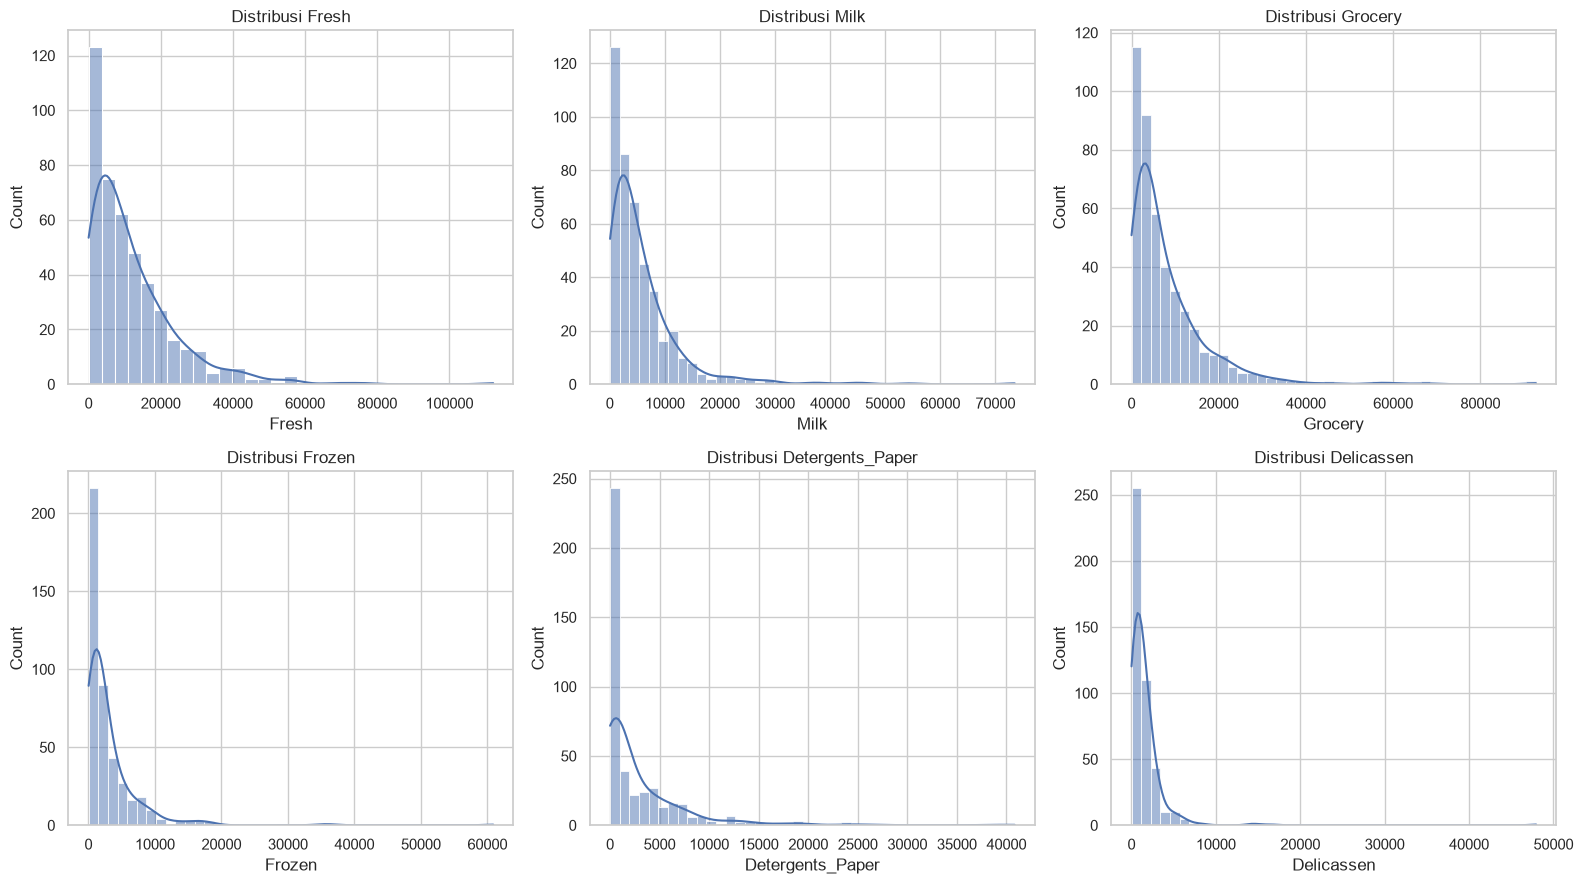

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9)) #

for ax, col in zip(axes.ravel(), features):
    sns.histplot(X[col], kde=True, ax=ax)
    ax.set_title(f"Distribusi {col}")

plt.tight_layout()
plt.show()

## 7. Standardisasi

Standardisasi dilakukan sekali dan hasilnya digunakan untuk **K-Means maupun Hierarchical Clustering**, sehingga kedua metode dapat dibandingkan secara adil.

In [11]:
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

X_scaled_df = pd.DataFrame(X_scaled, columns=features)

print("Data setelah standardisasi:")
display(X_scaled_df.head())

print("Mean setelah standardisasi:")
display(X_scaled_df.mean().round(4))

print("Std setelah standardisasi:")
display(X_scaled_df.std().round(4))

Data setelah standardisasi:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
0,0.052933,0.523568,-0.041115,-0.589367,-0.043569,-0.066339
1,-0.391302,0.544458,0.170318,-0.270136,0.086407,0.089151
2,-0.447029,0.408538,-0.028157,-0.137536,0.133232,2.243293
3,0.100111,-0.624020,-0.392977,0.687144,-0.498588,0.093411
4,0.840239,-0.052396,-0.079356,0.173859,-0.231918,1.299347


Mean setelah standardisasi:


Fresh              -0.0
Milk                0.0
Grocery            -0.0
Frozen              0.0
Detergents_Paper    0.0
Delicassen         -0.0
dtype: float64

Std setelah standardisasi:


Fresh               1.0011
Milk                1.0011
Grocery             1.0011
Frozen              1.0011
Detergents_Paper    1.0011
Delicassen          1.0011
dtype: float64

## 8. K-Means — Elbow Method

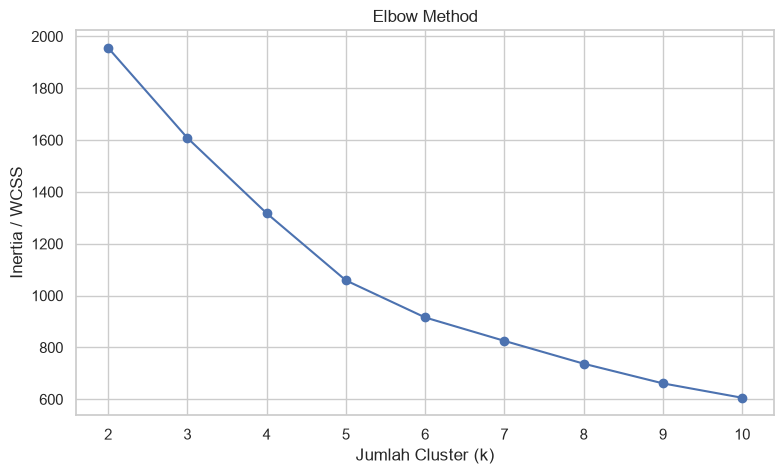

In [12]:
k_range = range(2, 11)
inertia = []

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(k_range), inertia, marker="o")
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Inertia / WCSS")
plt.title("Elbow Method")
plt.xticks(list(k_range))
plt.show()

## 9. Silhouette Score untuk Beberapa Nilai k

Silhouette Score digunakan bersama Elbow Method untuk membantu menentukan jumlah cluster.

,k,Silhouette Score
0,2,0.547215
1,3,0.548287
2,4,0.348471
3,5,0.369040
4,6,0.378229
5,7,0.334282
6,8,0.320116
7,9,0.309028
8,10,0.311214


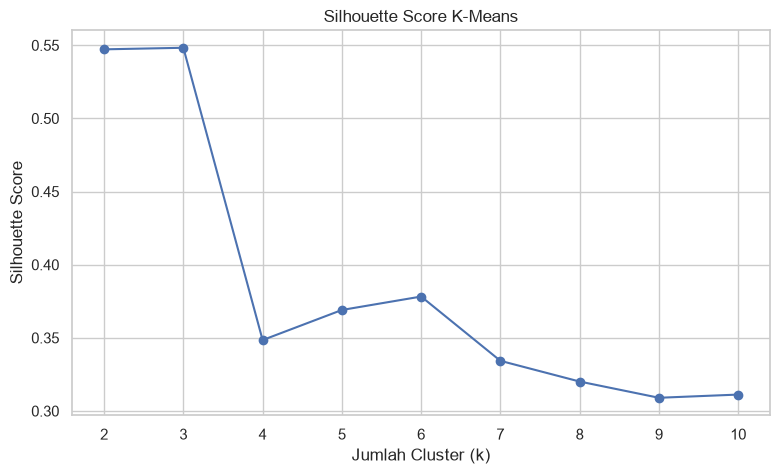

Nilai k dengan Silhouette Score tertinggi: k = 3, score = 0.5483


In [13]:
silhouette_k = {}

for k in k_range:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    labels = kmeans.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)
    silhouette_k[k] = score

silhouette_k_df = pd.DataFrame({
    "k": list(silhouette_k.keys()),
    "Silhouette Score": list(silhouette_k.values())
})

display(silhouette_k_df)

plt.figure(figsize=(9, 5))
plt.plot(
    silhouette_k_df["k"],
    silhouette_k_df["Silhouette Score"],
    marker="o"
)
plt.xlabel("Jumlah Cluster (k)")
plt.ylabel("Silhouette Score")
plt.title("Silhouette Score K-Means")
plt.xticks(list(k_range))
plt.show()

best_k_silhouette = max(silhouette_k, key=silhouette_k.get)
print(
    f"Nilai k dengan Silhouette Score tertinggi: "
    f"k = {best_k_silhouette}, "
    f"score = {silhouette_k[best_k_silhouette]:.4f}"
)

## 10. Menentukan Jumlah Cluster K-Means

Gunakan **Elbow Method dan Silhouette Score secara bersama-sama**.

Jika hasil keduanya tidak menunjuk angka yang sama, pertimbangkan bentuk elbow dan nilai silhouette, lalu pilih jumlah cluster yang paling masuk akal untuk analisis.

In [14]:
# Ubah nilai ini setelah melihat grafik Elbow dan tabel Silhouette.
# Untuk dataset Wholesale Customers dengan standardisasi,
# nilai awal yang sering digunakan adalah 2.
chosen_k = 2

print("Jumlah cluster K-Means yang digunakan:", chosen_k)

Jumlah cluster K-Means yang digunakan: 2


## 11. Menerapkan K-Means

In [15]:
kmeans_final = KMeans(
    n_clusters=chosen_k,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X_scaled)

df_kmeans = df.copy()
df_kmeans["KMeans_Cluster"] = kmeans_labels

kmeans_silhouette = silhouette_score(X_scaled, kmeans_labels)

print(f"Silhouette Score K-Means: {kmeans_silhouette:.4f}")
print("\nJumlah anggota tiap cluster:")
display(df_kmeans["KMeans_Cluster"].value_counts().sort_index())

Silhouette Score K-Means: 0.5472

Jumlah anggota tiap cluster:


KMeans_Cluster
0    389
1     51
Name: count, dtype: int64

## 12. Visualisasi K-Means dengan PCA

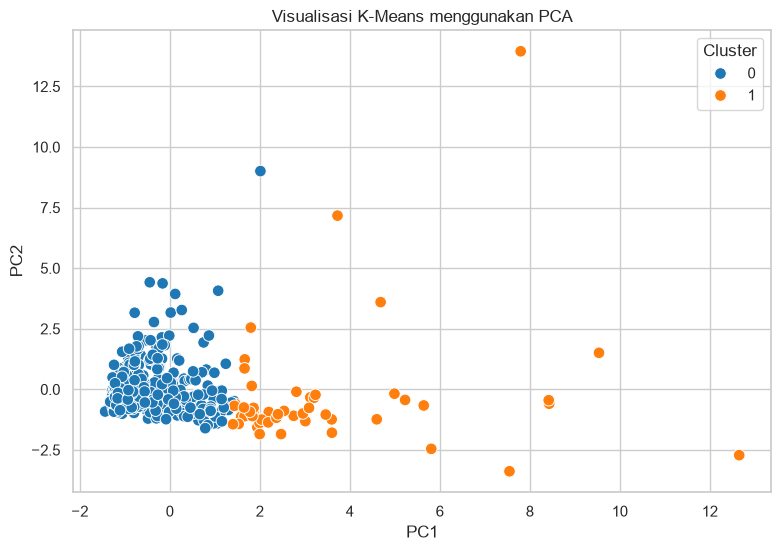

Variance explained PC1 + PC2: 72.46%


In [16]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_scaled)

pca_kmeans = pd.DataFrame({
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": kmeans_labels
})

plt.figure(figsize=(9, 6))
sns.scatterplot(
    data=pca_kmeans,
    x="PC1",
    y="PC2",
    hue="Cluster",
    palette="tab10",
    s=70
)
plt.title("Visualisasi K-Means menggunakan PCA")
plt.show()

print(
    f"Variance explained PC1 + PC2: "
    f"{pca.explained_variance_ratio_.sum():.2%}"
)

## 13. Profil Cluster K-Means

In [17]:
kmeans_profile = df_kmeans.groupby("KMeans_Cluster")[features].mean().round(2)

print("Rata-rata fitur setiap cluster:")
display(kmeans_profile)

print("Jumlah anggota setiap cluster:")
display(
    df_kmeans["KMeans_Cluster"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Pelanggan")
    .to_frame()
)

Rata-rata fitur setiap cluster:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
KMeans_Cluster,,,,,,
0,12157.30,4028.17,5402.72,3066.07,1667.69,1256.89
1,10802.76,19282.33,27390.25,3116.67,12139.73,3568.84


Jumlah anggota setiap cluster:


,Jumlah Pelanggan
KMeans_Cluster,
0,389
1,51


### Visualisasi Profil K-Means

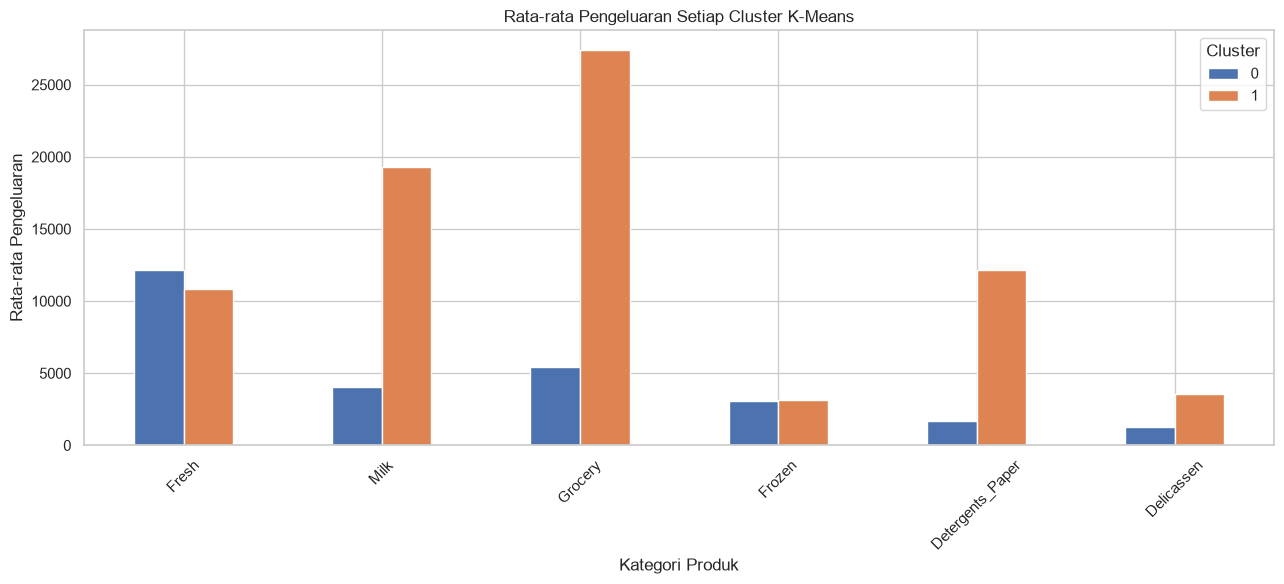

In [18]:
kmeans_profile.T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Rata-rata Pengeluaran Setiap Cluster K-Means")
plt.xlabel("Kategori Produk")
plt.ylabel("Rata-rata Pengeluaran")
plt.xticks(rotation=45)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

## 14. Analisis Karakteristik Cluster K-Means

Gunakan tabel rata-rata di atas untuk menjelaskan cluster.

Contoh cara membaca:
- Cluster dengan rata-rata `Fresh` paling tinggi berarti pelanggan pada cluster tersebut memiliki pengeluaran relatif tinggi pada kategori Fresh.
- Lakukan hal yang sama untuk `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, dan `Delicassen`.
- Jangan menyimpulkan karakteristik hanya berdasarkan jumlah anggota cluster.

# B. HIERARCHICAL CLUSTERING

## 15. Agglomerative Clustering — Ward, Average, Complete, Single

Semua metode menggunakan **X_scaled yang sama** seperti K-Means.

In [19]:
linkages = ["ward", "average", "complete", "single"]
hierarchical_results = []

hierarchical_labels = {}

for method in linkages:
    model = AgglomerativeClustering(
        n_clusters=chosen_k,
        linkage=method
    )

    labels = model.fit_predict(X_scaled)
    score = silhouette_score(X_scaled, labels)

    hierarchical_labels[method] = labels

    hierarchical_results.append({
        "Linkage": method,
        "Silhouette Score": score
    })

hierarchical_scores = pd.DataFrame(hierarchical_results)

display(
    hierarchical_scores.sort_values(
        "Silhouette Score",
        ascending=False
    ).reset_index(drop=True)
)

,Linkage,Silhouette Score
0,average,0.863801
1,complete,0.863801
2,single,0.863801
3,ward,0.792457


## 16. Visualisasi Perbandingan Silhouette Score

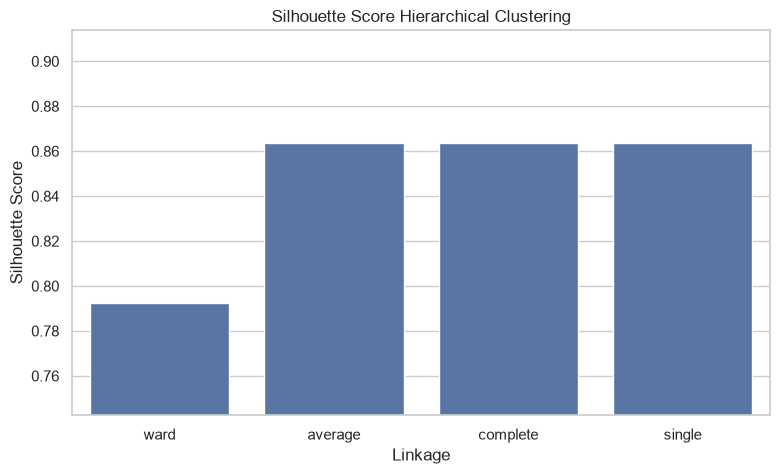

Linkage dengan Silhouette Score tertinggi: average
Silhouette Score: 0.8638


In [20]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=hierarchical_scores,
    x="Linkage",
    y="Silhouette Score"
)

plt.title("Silhouette Score Hierarchical Clustering")
plt.ylim(
    hierarchical_scores["Silhouette Score"].min() - 0.05,
    hierarchical_scores["Silhouette Score"].max() + 0.05
)
plt.show()

best_linkage = hierarchical_scores.loc[
    hierarchical_scores["Silhouette Score"].idxmax(),
    "Linkage"
]

best_hierarchical_score = hierarchical_scores["Silhouette Score"].max()

print("Linkage dengan Silhouette Score tertinggi:", best_linkage)
print(f"Silhouette Score: {best_hierarchical_score:.4f}")

## 17. Dendrogram Ward

Dendrogram digunakan untuk melihat struktur penggabungan data dan membantu menentukan jumlah cluster yang wajar.

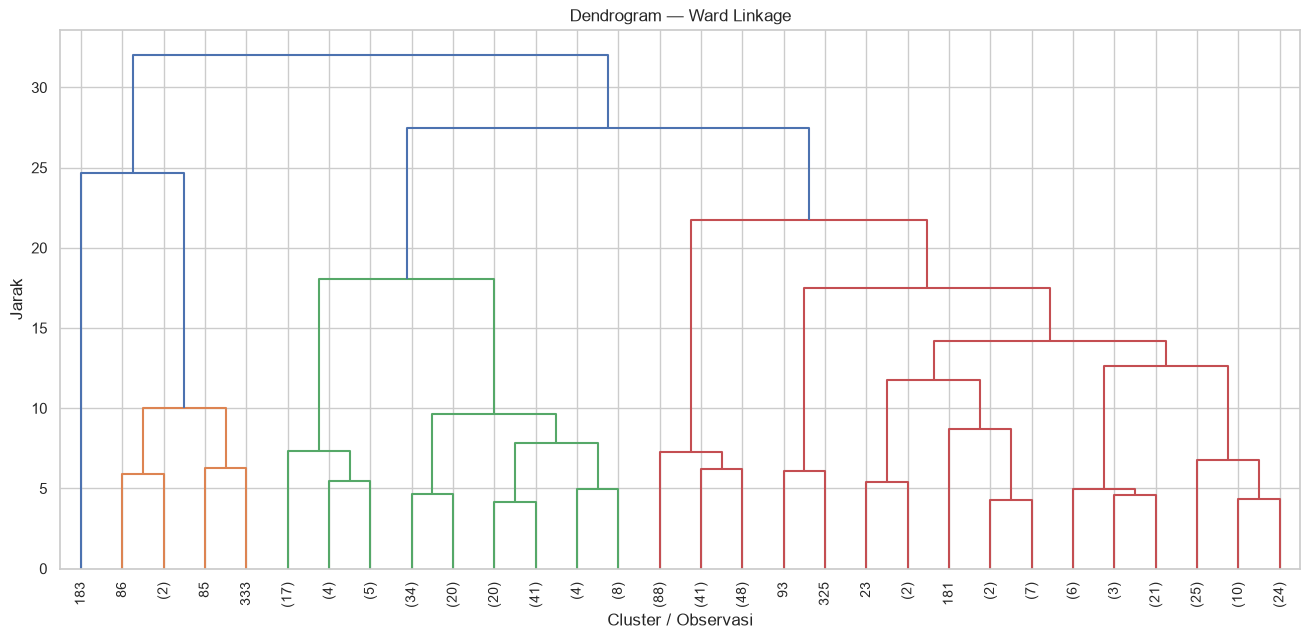

In [21]:
ward_linkage = linkage(X_scaled, method="ward")

plt.figure(figsize=(16, 7))
dendrogram(
    ward_linkage,
    truncate_mode="lastp",
    p=30,
    leaf_rotation=90,
    leaf_font_size=10
)

plt.title("Dendrogram — Ward Linkage")
plt.xlabel("Cluster / Observasi")
plt.ylabel("Jarak")
plt.show()

### Menentukan jumlah cluster dari Dendrogram

Perhatikan lonjakan vertikal terbesar pada dendrogram. Garis potong horizontal dapat digunakan sebagai bantuan visual.

Jumlah cluster pada Hierarchical di bawah dibuat sama dengan `chosen_k` agar perbandingan dengan K-Means menggunakan jumlah cluster yang konsisten, kecuali kamu memilih jumlah berbeda berdasarkan dendrogram.

In [22]:
hierarchical_k = chosen_k

print("Jumlah cluster Hierarchical yang digunakan:", hierarchical_k)

Jumlah cluster Hierarchical yang digunakan: 2


## 18. Membuat Label Hierarchical Ward

In [23]:
ward_model = AgglomerativeClustering(
    n_clusters=hierarchical_k,
    linkage="ward"
)

ward_labels = ward_model.fit_predict(X_scaled)

df_hierarchical = df.copy()
df_hierarchical["Hierarchical_Ward"] = ward_labels

ward_score = silhouette_score(X_scaled, ward_labels)

print(f"Silhouette Score Ward: {ward_score:.4f}")
print("\nJumlah anggota setiap cluster:")
display(
    df_hierarchical["Hierarchical_Ward"]
    .value_counts()
    .sort_index()
)

Silhouette Score Ward: 0.7925

Jumlah anggota setiap cluster:


Hierarchical_Ward
0    434
1      6
Name: count, dtype: int64

## 19. Heatmap Data Terstandardisasi berdasarkan Cluster Ward

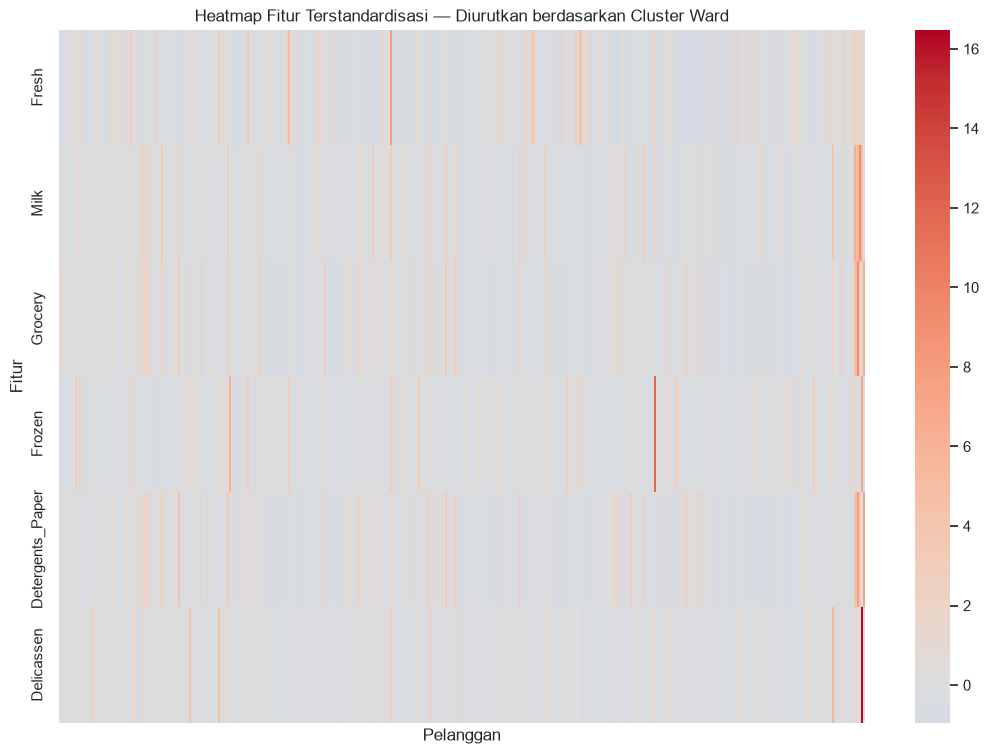

In [24]:
heatmap_df = X_scaled_df.copy()
heatmap_df["Cluster"] = ward_labels

heatmap_df = heatmap_df.sort_values("Cluster")

plt.figure(figsize=(13, 9))

sns.heatmap(
    heatmap_df[features].T,
    cmap="coolwarm",
    center=0,
    xticklabels=False,
    yticklabels=True
)

plt.title("Heatmap Fitur Terstandardisasi — Diurutkan berdasarkan Cluster Ward")
plt.xlabel("Pelanggan")
plt.ylabel("Fitur")
plt.show()

## 20. Profil Cluster Hierarchical Ward

In [25]:
ward_profile = df_hierarchical.groupby(
    "Hierarchical_Ward"
)[features].mean().round(2)

print("Rata-rata fitur setiap cluster Ward:")
display(ward_profile)

print("Jumlah anggota setiap cluster:")
display(
    df_hierarchical["Hierarchical_Ward"]
    .value_counts()
    .sort_index()
    .rename("Jumlah Pelanggan")
    .to_frame()
)

Rata-rata fitur setiap cluster Ward:


,Fresh,Milk,Grocery,Frozen,Detergents_Paper,Delicassen
Hierarchical_Ward,,,,,,
0,11786.33,5274.43,7306.52,2999.85,2575.45,1404.28
1,27477.00,43542.17,54588.50,8285.67,25018.33,10247.83


Jumlah anggota setiap cluster:


,Jumlah Pelanggan
Hierarchical_Ward,
0,434
1,6


## 21. Visualisasi Profil Cluster Ward

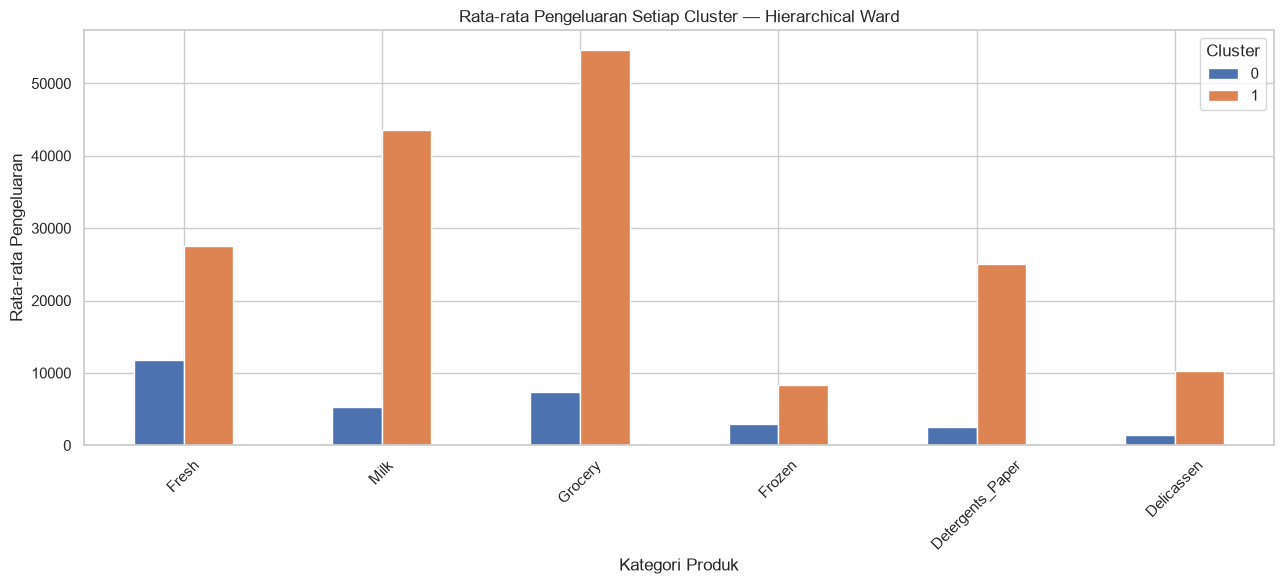

In [26]:
ward_profile.T.plot(
    kind="bar",
    figsize=(13, 6)
)

plt.title("Rata-rata Pengeluaran Setiap Cluster — Hierarchical Ward")
plt.xlabel("Kategori Produk")
plt.ylabel("Rata-rata Pengeluaran")
plt.xticks(rotation=45)
plt.legend(title="Cluster")
plt.tight_layout()
plt.show()

# C. PERBANDINGAN K-MEANS DAN HIERARCHICAL

## 22. Ringkasan Hasil

In [27]:
comparison = pd.DataFrame({
    "Metode": ["K-Means", "Hierarchical Ward"],
    "Jumlah Cluster": [chosen_k, hierarchical_k],
    "Silhouette Score": [kmeans_silhouette, ward_score]
})

display(comparison)

,Metode,Jumlah Cluster,Silhouette Score
0,K-Means,2,0.547215
1,Hierarchical Ward,2,0.792457


## 23. Perbandingan Jumlah Anggota Cluster

In [28]:
kmeans_counts = (
    df_kmeans["KMeans_Cluster"]
    .value_counts()
    .sort_index()
)

ward_counts = (
    df_hierarchical["Hierarchical_Ward"]
    .value_counts()
    .sort_index()
)

cluster_comparison = pd.DataFrame({
    "K-Means": kmeans_counts,
    "Hierarchical Ward": ward_counts
}).fillna(0).astype(int)

display(cluster_comparison)

,K-Means,Hierarchical Ward
0,389,434
1,51,6


## 24. Perbandingan Profil Cluster

Perhatikan tabel profil K-Means dan Ward.

Hal yang perlu dibahas:
1. Apakah jumlah cluster sama?
2. Apakah jumlah anggota tiap cluster mirip atau berbeda?
3. Apakah cluster memiliki pola pengeluaran yang serupa?
4. Apakah pelanggan dengan pengeluaran tinggi pada kategori tertentu masuk ke kelompok yang sama?
5. Bagaimana perbedaan Silhouette Score kedua metode?

# Jawaban Analisis — Template

### A. K-Means
**1. Berdasarkan Elbow Method dan Silhouette Score, berapa jumlah cluster yang digunakan?**

Jumlah cluster yang digunakan adalah **[isi sesuai hasil grafik]**. Pemilihan tersebut didasarkan pada bentuk Elbow Method dan nilai Silhouette Score. Elbow digunakan untuk melihat titik ketika penurunan WCSS mulai melandai, sedangkan Silhouette Score digunakan untuk menilai kualitas pemisahan cluster.

**2. Bagaimana karakteristik setiap cluster?**

Karakteristik cluster dijelaskan berdasarkan nilai rata-rata `Fresh`, `Milk`, `Grocery`, `Frozen`, `Detergents_Paper`, dan `Delicassen` pada tabel profil K-Means.

### B. Hierarchical
**1. Linkage mana yang menghasilkan Silhouette Score paling tinggi?**

Linkage dengan Silhouette Score paling tinggi adalah **[isi dari tabel hasil]**. Nilai tersebut menunjukkan bahwa, dibandingkan linkage lain yang diuji pada preprocessing dan jumlah cluster yang sama, pembagian cluster tersebut memiliki kualitas pemisahan yang lebih tinggi berdasarkan metrik Silhouette.

**2. Berdasarkan dendrogram Ward, berapa jumlah cluster yang paling wajar?**

Jumlah cluster yang dianggap wajar adalah **[isi berdasarkan dendrogram]**. Dasarnya adalah pemotongan dendrogram pada bagian sebelum/sekitar lonjakan jarak penggabungan yang besar.

### C. Perbandingan
K-Means dan Hierarchical diterapkan pada dataset serta hasil standardisasi yang sama. Perbedaan hasil dapat dilihat dari label cluster, jumlah anggota setiap cluster, profil rata-rata fitur, dan Silhouette Score.

## 25. Catatan

Notebook ini sengaja menghitung semua nilai dari dataset yang digunakan, sehingga hasil numerik tidak dibuat secara manual.

Jika `chosen_k` diubah berdasarkan hasil analisis Elbow dan Silhouette, jalankan kembali sel-sel setelah bagian tersebut agar K-Means dan Hierarchical menggunakan jumlah cluster yang sesuai.